# LAB1 - Bài 5 (Titanic): Số người đi cùng và khả năng sống sót

**Họ tên:** Đinh Công Vinh Quang  
**MSSV:** 6451071061

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

HO_TEN, MSSV = "Đinh Công Vinh Quang", "6451071061"
print(f"{HO_TEN} - {MSSV}")

Đinh Công Vinh Quang - 6451071061


In [2]:
df = pd.read_csv("titanic.csv")
df["family_size"] = df["sibsp"] + df["parch"]          # số người thân đi cùng
print("Đi một mình:", (df["family_size"] == 0).sum(), "người")
print("Đi cùng người thân:", (df["family_size"] > 0).sum(), "người")
print()
print(df["family_size"].value_counts().sort_index())

Đi một mình: 790 người
Đi cùng người thân: 519 người

family_size
0     790
1     235
2     159
3      43
4      22
5      25
6      16
7       8
10     11
Name: count, dtype: int64


              mean  count
family_size              
0            0.303    790
1            0.536    235
2            0.566    159
3            0.698     43
4            0.273     22
5            0.200     25
6            0.250     16
7            0.000      8
10           0.000     11


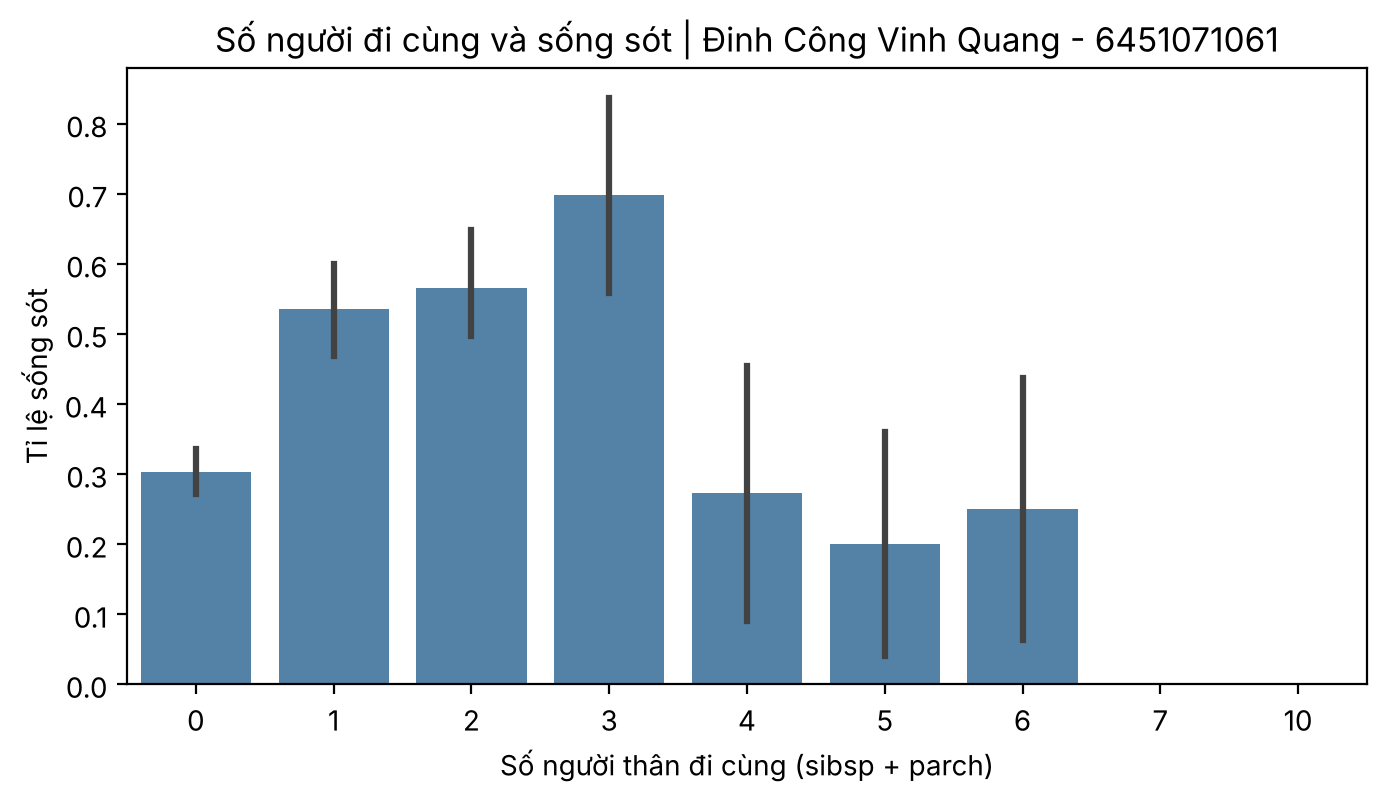

In [3]:
rate = df.groupby("family_size")["survived"].agg(["mean", "count"]).round(3)
print(rate)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, x="family_size", y="survived", color="steelblue", ax=ax)
ax.set_xlabel("Số người thân đi cùng (sibsp + parch)"); ax.set_ylabel("Tỉ lệ sống sót")
ax.set_title(f"Số người đi cùng và sống sót | {HO_TEN} - {MSSV}")
plt.show()

**Nhận xét:**
- Có 790 người đi một mình và 519 người đi cùng người thân.
- Người đi một mình sống sót ~30%, thấp hơn nhóm có 1–3 người thân đi cùng (~54–70%).
- Nhóm đi đông người (4 người thân trở lên) tỉ lệ sống thấp trở lại (khoảng 20–27%), và nhóm 7–10 người thân đi cùng gần như không ai sống sót (0%).